# IND320 Project work, part 3: Data quality

**Haakon Risbråthe**

[GitHub repository](https://github.com/Haakon5555/ind320-haakon5555) · [Streamlit app](https://ind320-haakon5555-bfhbsiaysptxoqxqkwr8o4.streamlit.app/)

## 1. Region boundaries and weather locations

The assignment asks for boundaries for electricity areas and precipitation areas, and 1000 random locations in each region. This section prepares the three precipitation areas from the NVE region boundaries and the five electricity price areas NO1–NO5 from the bidding area boundaries. We sample 1000 locations separately within each of these eight areas. The two geographical divisions overlap, but are kept separate so that weather can be summarised for the same area as the reservoir data.

Sources:

- [Assignment](https://nmbu.instructure.com/courses/14185/assignments/59074), under **Jupyter Notebook**.
- [NVE Atlas](https://atlas.nve.no/) and the [NVE_Region layer description](https://kart.nve.no/enterprise/rest/services/Mapservices/Administrasjon2/MapServer/0).
- [NVE bidding area layer](https://kart.nve.no/enterprise/rest/services/Nettomraader/MapServer/0).

### 1.1 Read the source regions

A shapefile stores polygon coordinates and attributes. GeoPandas reads them into a table with a `geometry` column. Each row here represents one of the five NVE administrative regions.

The `.shp`, `.shx`, `.dbf` and `.prj` files belong together. The original files are read without modification. The coordinate system, EPSG:25833, uses metres, allowing area calculations in square metres.

In [1]:
from itertools import combinations
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from shapely.geometry import Polygon

source_file = Path("data/NVE_Region.shp")

# This export has no .cpg file, so specify the text encoding explicitly.
regions = gpd.read_file(source_file, encoding="UTF-8")
assert set(regions["REGION"]) == {"RØ", "RS", "RV", "RM", "RN"}
assert len(regions) == 5
assert regions.crs.to_epsg() == 25833
assert regions.is_valid.all() and not regions.is_empty.any()

display(regions[["REGION", "REGIONNAVN"]])

,REGION,REGIONNAVN
0,RV,Region Vest
1,RM,Region Midt-Norge
2,RN,Region Nord
3,RØ,Region Øst
4,RS,Region Sør


### 1.2 Merge five regions into three areas

The assignment notes that East is split into RS + RØ, and North into RM + RN. We combine these pairs and keep RV as West:

| Area | Source regions |
| --- | --- |
| East (Øst) | RØ + RS |
| West (Vest) | RV |
| North (Nord) | RM + RN |

`region_mapping` defines the groups. `map()` gives each original row an area name, without changing its geometry. `dissolve(by="area")` then joins the polygons with the same name and removes their shared internal borders. The result has three rows.

These boundaries follow the course example using administrative regions. They include sea areas and are not clipped to land or individual reservoir catchments.

In [2]:
region_mapping = {
    "RØ": "East", "RS": "East", "RV": "West", "RM": "North", "RN": "North"
}
regions["area"] = regions["REGION"].map(region_mapping)

# Join the polygons within each group, then choose a consistent row order.
areas = regions[["area", "geometry"]].dissolve(by="area")
areas = areas.loc[["East", "West", "North"]].reset_index()
areas["source_regions"] = ["RØ + RS", "RV", "RM + RN"]
areas["area_km2"] = areas.geometry.area / 1_000_000

assert areas.is_valid.all() and not areas.is_empty.any()
display(areas[["area", "source_regions", "area_km2"]])

,area,source_regions,area_km2
0,East,RØ + RS,138365.851896
1,West,RV,75413.959489
2,North,RM + RN,256327.303816


### 1.3 Check the merged geometry

Merging should preserve the total geographical coverage. `union_all()` combines all polygons into one geometry. `symmetric_difference()` finds any area covered by only one of the two versions. Its area should be zero.

We also check that the three resulting areas do not overlap. Shared borders are allowed because lines have zero area. Small gaps already present in the source are measured and preserved.

In [3]:
original_geometry = regions.geometry.union_all()
merged_geometry = areas.geometry.union_all()
changed_area = original_geometry.symmetric_difference(merged_geometry).area
assert changed_area == 0

for first_area, second_area in combinations(areas.geometry, 2):
    assert first_area.intersection(second_area).area == 0

# Interior rings represent gaps in the combined source geometry.
gaps = [Polygon(ring) for ring in original_geometry.interiors]
gap_area = sum(gap.area for gap in gaps)
print(f"Changed area: {changed_area:.0f} m². No overlap between merged areas.")
print(f"Source gaps preserved: {len(gaps)}, covering {gap_area:.6f} m².")

Changed area: 0 m². No overlap between merged areas.
Source gaps preserved: 34, covering 2.336901 m².


### 1.4 Draw the comparison map

The map is drawn from the polygon coordinates in `geometry`. GeoPandas uses Matplotlib to fill each polygon and draw its outline.

`plt.subplots(1, 2)` creates a figure with two panels. `regions.plot()` draws the five original regions on the left. `areas.plot()` draws the three merged areas on the right. Colours show which original regions belong together. Dotted lines on the right mark the original borders.

`representative_point()` provides a position inside each polygon for its label. Equal axis scales preserve the map proportions. `plt.show()` displays the figure directly in this notebook, and the displayed image is stored with the notebook when it is saved. A separate PNG can be exported with `fig.savefig(...)` if needed.

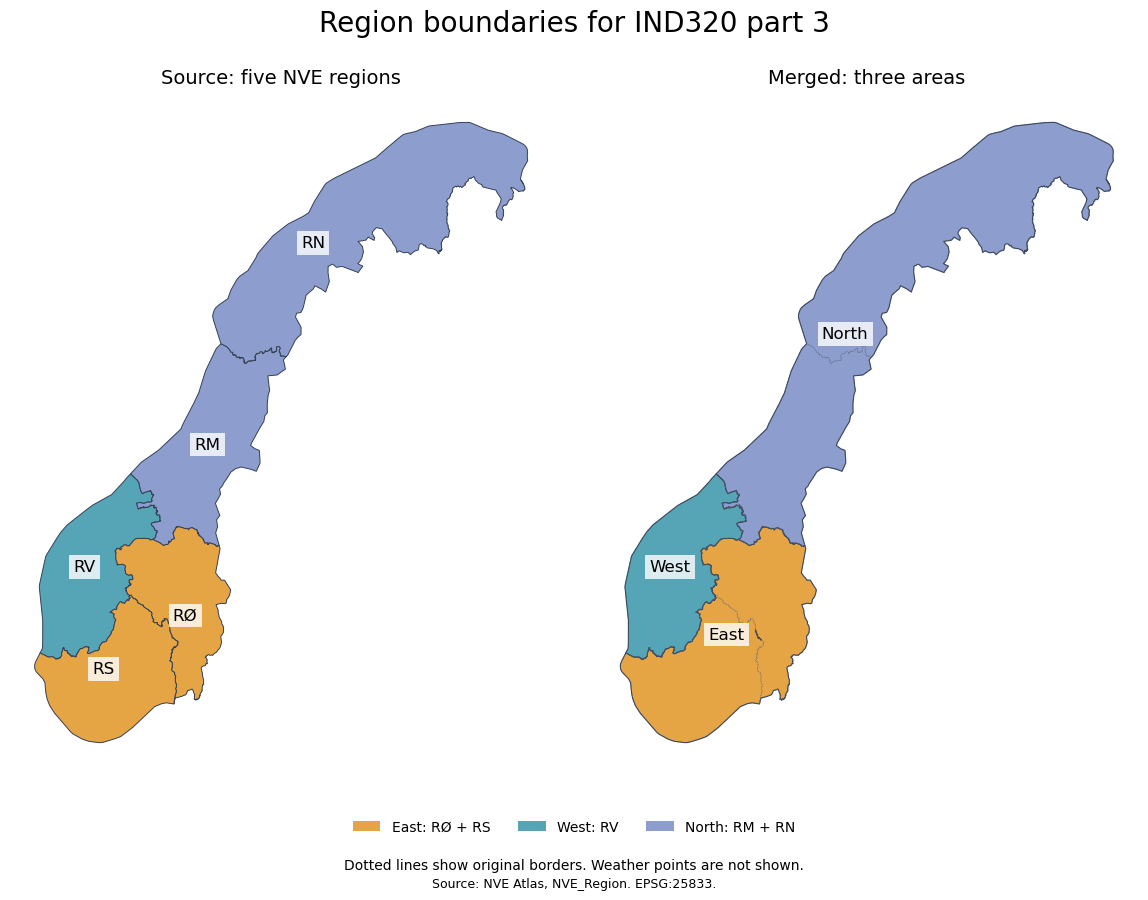

In [4]:
colors = {"East": "#E6A545", "West": "#56A5B6", "North": "#8D9DCE"}
fig, axes = plt.subplots(1, 2, figsize=(12, 9), facecolor="white")
for axis in axes:
    axis.set_facecolor("#F4F6F8")
    axis.set_aspect("equal")
    axis.set_axis_off()

# Left panel: original polygons with their original region codes.
regions.plot(ax=axes[0], color=regions["area"].map(colors),
             edgecolor="#344054", linewidth=0.7)
for _, row in regions.iterrows():
    label_point = row.geometry.representative_point()
    axes[0].text(label_point.x, label_point.y, row["REGION"],
                 ha="center", va="center", fontsize=12,
                 bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=3))
axes[0].set_title("Source: five NVE regions", fontsize=14)

# Right panel: merged polygons, with original borders shown as dotted lines.
areas.plot(ax=axes[1], color=areas["area"].map(colors),
           edgecolor="#344054", linewidth=0.8)
regions.boundary.plot(ax=axes[1], color="#596579", linewidth=0.45, linestyle=":")
for _, row in areas.iterrows():
    label_point = row.geometry.representative_point()
    axes[1].text(label_point.x, label_point.y, row["area"],
                 ha="center", va="center", fontsize=12,
                 bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=3))
axes[1].set_title("Merged: three areas", fontsize=14)

# Add a shared legend and source information below the maps.
legend_items = [
    Patch(facecolor=colors[row["area"]],
          label=f"{row['area']}: {row['source_regions']}")
    for _, row in areas.iterrows()
]
fig.suptitle("Region boundaries for IND320 part 3", fontsize=20)
fig.legend(handles=legend_items, loc="lower center", ncol=3,
           frameon=False, bbox_to_anchor=(0.5, 0.05))
fig.text(0.5, 0.025, "Dotted lines show original borders. Weather points are not shown.",
         ha="center", fontsize=10)
fig.text(0.5, 0.005, "Source: NVE Atlas, NVE_Region. EPSG:25833.",
         ha="center", fontsize=9)
fig.subplots_adjust(left=0.03, right=0.97, top=0.9, bottom=0.12, wspace=0.08)
plt.show()

### 1.5 Sample 1000 locations in each area

The merged polygons are already available in `areas`, so they can be used directly without saving and reopening an intermediate file.

`sample_points()` draws random locations inside each polygon. Sampling takes place in the projected coordinate system. The fixed seed, `rng=42`, makes the draw reproducible with this environment and input order. Each row of `points_per_region` contains a MultiPoint geometry holding 1000 points.

The three areas produce 3000 points. The checks below confirm the count and that every point lies inside its assigned area.

In [5]:
points_per_area = 1000
points_per_region = areas.geometry.sample_points(size=points_per_area, rng=42)

for index, multipoint in points_per_region.items():
    assert len(multipoint.geoms) == points_per_area
    assert all(areas.geometry.loc[index].contains(point) for point in multipoint.geoms)
    print(f"{areas.loc[index, 'area']}: {len(multipoint.geoms)} points")

East: 1000 points
West: 1000 points
North: 1000 points


### 1.6 Convert the points to longitude and latitude

The weather API needs geographical coordinates rather than projected metre coordinates. `to_crs(epsg=4326)` transforms the points to WGS84. In this coordinate system, `x` is longitude and `y` is latitude.

`coordinates_per_region` stores one list of `(longitude, latitude)` pairs for each area. These lists can be passed to the weather download step. No weather data are downloaded here.

In [6]:
points_wgs84 = points_per_region.to_crs(epsg=4326)
coordinates_per_region = {}

for index, multipoint in points_wgs84.items():
    region_name = areas.loc[index, "area"]
    coordinates_per_region[region_name] = []

    for point in multipoint.geoms:
        latitude = point.y
        longitude = point.x
        coordinates_per_region[region_name].append((longitude, latitude))

    # Display a small sample, rather than printing all 1000 pairs.
    print(f"{region_name}, first three (longitude, latitude) pairs:")
    print(coordinates_per_region[region_name][:3])

assert points_wgs84.crs.to_epsg() == 4326
assert sum(len(points) for points in coordinates_per_region.values()) == 3000

East, first three (longitude, latitude) pairs:
[(6.743984314994531, 57.94538082983031), (9.076473401056122, 59.91419049556114), (8.193685388283756, 60.7342973287599)]
West, first three (longitude, latitude) pairs:
[(6.334796150295968, 60.616448094885584), (4.351736259168014, 60.78186897933524), (7.031672988900803, 63.25804198909316)]
North, first three (longitude, latitude) pairs:
[(24.97181428897678, 69.37720353277649), (23.177668855757382, 69.95939029939014), (18.423432821730692, 68.60154028538581)]


### 1.7 Read the electricity price areas

The bidding area shapefile contains NO1–NO5. These polygons are used directly, without merging them. The source field `budomr` is preserved, while `area` provides consistent names without spaces.

For example, NO3 corresponds to reservoir records with `area_type == "EL"` and `area_number == 3`. A weather summary for NO3 must use points within this polygon. The three precipitation areas are a separate choice of geographical grouping.

We check that all five areas are present, their geometries are valid, and they do not overlap each other. Overlap with the precipitation areas is expected because the two maps describe the same country using different boundaries.

In [7]:
electricity_source_file = Path("data/Budområder.shp")
electricity_areas = gpd.read_file(electricity_source_file, encoding="UTF-8")
electricity_areas["area"] = electricity_areas["budomr"].str.replace(" ", "", regex=False)
electricity_areas = electricity_areas.sort_values("area").reset_index(drop=True)

assert len(electricity_areas) == 5
assert set(electricity_areas["area"]) == {"NO1", "NO2", "NO3", "NO4", "NO5"}
assert electricity_areas.crs.to_epsg() == 25833
assert electricity_areas.is_valid.all() and not electricity_areas.is_empty.any()
for first_area, second_area in combinations(electricity_areas.geometry, 2):
    assert first_area.intersection(second_area).area == 0

electricity_areas["area_km2"] = electricity_areas.geometry.area / 1_000_000
display(electricity_areas[["budomr", "area", "area_km2"]])

,budomr,area,area_km2
0,NO 1,NO1,60529.018621
1,NO 2,NO2,68759.689039
2,NO 3,NO3,104219.851962
3,NO 4,NO4,203250.012052
4,NO 5,NO5,33348.702814


### 1.8 Sample and convert electricity area locations

We draw 1000 points inside each electricity area using the same projected coordinate system and fixed random seed as above. Each point is checked against its own area boundary before conversion to WGS84.

The five new coordinate lists are added to `coordinates_per_region`. It then contains eight named lists: East, West, North, and NO1–NO5, with 8000 sampled locations in total. These are separate samples for two alternative geographical groupings, not one combined sample for a national average.

`coordinates_per_region["NO3"]` contains the 1000 `(longitude, latitude)` pairs for the NO3 weather request. No weather data are downloaded in this section.

In [8]:
electricity_points = electricity_areas.geometry.sample_points(
    size=points_per_area, rng=42
)
for index, multipoint in electricity_points.items():
    assert len(multipoint.geoms) == points_per_area
    assert all(electricity_areas.geometry.loc[index].contains(point)
               for point in multipoint.geoms)

electricity_points_wgs84 = electricity_points.to_crs(epsg=4326)
for index, multipoint in electricity_points_wgs84.items():
    area_name = electricity_areas.loc[index, "area"]
    coordinates_per_region[area_name] = [
        (point.x, point.y) for point in multipoint.geoms
    ]

expected_areas = {"East", "West", "North", "NO1", "NO2", "NO3", "NO4", "NO5"}
assert electricity_points_wgs84.crs.to_epsg() == 4326
assert set(coordinates_per_region) == expected_areas
assert all(len(coordinates) == points_per_area
           for coordinates in coordinates_per_region.values())
assert all(-180 <= longitude <= 180 and -90 <= latitude <= 90
           for coordinates in coordinates_per_region.values()
           for longitude, latitude in coordinates)
assert sum(map(len, coordinates_per_region.values())) == 8000

for area_name, coordinates in coordinates_per_region.items():
    print(f"{area_name}: {len(coordinates)} locations")
print("Total: 8000 locations across eight separately sampled areas.")
print("NO3, first three (longitude, latitude) pairs:")
print(coordinates_per_region["NO3"][:3])

East: 1000 locations
West: 1000 locations
North: 1000 locations
NO1: 1000 locations
NO2: 1000 locations
NO3: 1000 locations
NO4: 1000 locations
NO5: 1000 locations
Total: 8000 locations across eight separately sampled areas.
NO3, first three (longitude, latitude) pairs:
[(9.528288121090178, 63.23031466835902), (9.354282633944061, 63.85102456368581), (5.395133355819768, 61.36875913933388)]


### 1.9 Show the electricity areas and sampled points

Each colour identifies one electricity area and its 1000 sampled locations. The map uses EPSG:25833 so that boundaries and points have the same coordinate system. The polygon check above verifies every point, including points close to borders that are difficult to distinguish on the map.

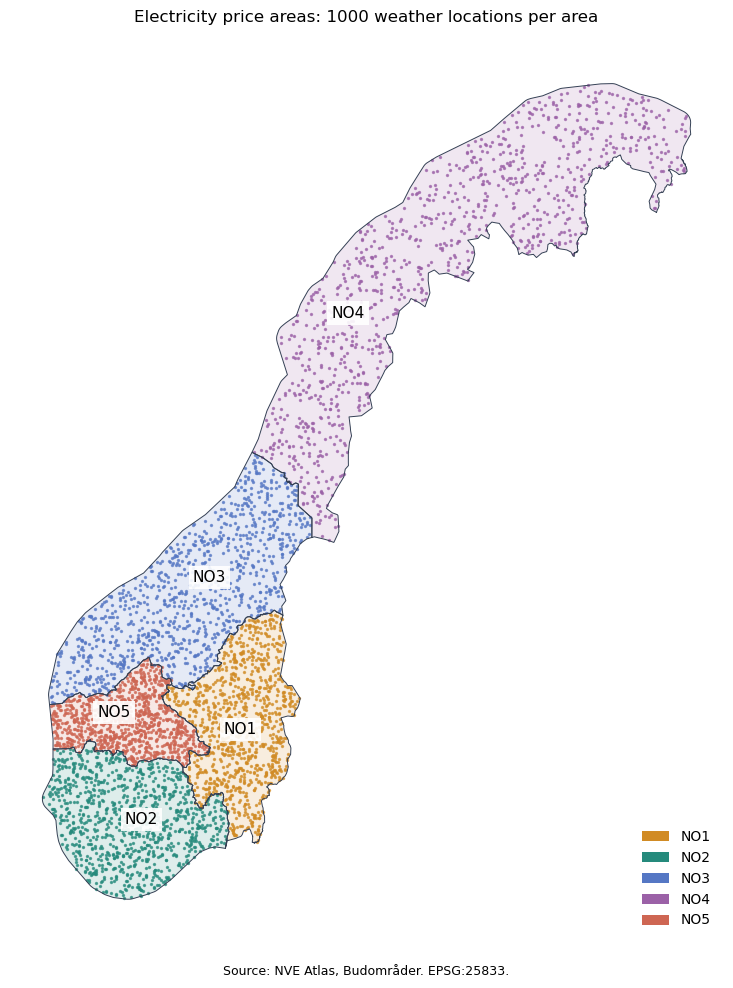

In [9]:
electricity_colors = {
    "NO1": "#D18B24", "NO2": "#258A7C", "NO3": "#5577C4",
    "NO4": "#9B61A7", "NO5": "#CE6653"
}
fig, ax = plt.subplots(figsize=(8, 10), facecolor="white")
for index, row in electricity_areas.iterrows():
    color = electricity_colors[row["area"]]
    electricity_areas.loc[[index]].plot(ax=ax, color=color, alpha=0.15)
    gpd.GeoSeries(list(electricity_points.loc[index].geoms),
                  crs=electricity_areas.crs).plot(
        ax=ax, color=color, markersize=2, alpha=0.7
    )
    label_point = row.geometry.representative_point()
    ax.text(label_point.x, label_point.y, row["area"],
            ha="center", va="center", fontsize=11,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.9, pad=3))
electricity_areas.boundary.plot(ax=ax, color="#344054", linewidth=0.7)
ax.set_aspect("equal")
ax.set_axis_off()
ax.set_title("Electricity price areas: 1000 weather locations per area", pad=15)
ax.legend(handles=[Patch(facecolor=color, label=area_name)
                   for area_name, color in electricity_colors.items()],
          loc="lower right", frameon=False)
fig.text(0.5, 0.02, "Source: NVE Atlas, Budområder. EPSG:25833.",
         ha="center", fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

## 2. Hourly weather from Open-Meteo

The [Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api) provides ERA5 reanalysis. We request `temperature_2m` in °C and `precipitation` in mm for each hour. Precipitation describes the preceding hour. Dates are inclusive, and timestamps use UTC.

The request parameters follow the documentation's generated Python example. We use `requests` and the documented JSON response to keep the download readable with the packages already used in part 2. Twenty coordinate pairs are sent together, but all 1000 locations are retained. The function accepts a region name and a date interval, and looks up the corresponding coordinates.

[Open-Meteo's quota](https://open-meteo.com/en/pricing) depends on duration, variables and locations. Saved raw responses allow interrupted downloads to resume, and complete arrays are reused on later runs. The limiter leaves headroom under the minute, hour and day limits. The hourly budget follows the [Open-Meteo reset logic](https://github.com/open-meteo/open-meteo/blob/main/Sources/App/Helper/Vapor/RateLimiter.swift), with a margin for the server reset and requests still in progress.

The default land-cell selection and elevation adjustment are retained. Requested coordinates and returned grid coordinates/elevations are stored separately. ERA5's approximate 25 km grid means nearby points can share weather information. These are model estimates, not 1000 independent weather stations.

In [10]:
# Export the same coordinates for the notebook and Streamlit app.
import json
Path("data/weather_locations.json").write_text(
    json.dumps(coordinates_per_region, separators=(",", ":"))
)


307318

In [11]:
from pathlib import Path
import gzip
import hashlib
import json
import time
import tempfile
import fcntl

import numpy as np
import pandas as pd
import requests

WEATHER_URL = "https://archive-api.open-meteo.com/v1/archive"
WEATHER_VARIABLES = ["temperature_2m", "precipitation"]


def _request_weather(params, cache_dir, progress=None):
    """Reuse an unchanged JSON response, or make one quota-limited request."""
    cache_dir = Path(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)
    request_key = hashlib.sha256(json.dumps(params, sort_keys=True).encode()).hexdigest()
    response_path = cache_dir / f"{request_key}.json.gz"
    if response_path.exists():
        with gzip.open(response_path, "rt") as source:
            return json.load(source)

    days = (pd.Timestamp(params["end_date"]) - pd.Timestamp(params["start_date"])).days + 1
    locations = len(params["latitude"].split(","))
    cost = locations * max(1, days / 14 * len(WEATHER_VARIABLES) / 10)
    # Leave headroom for interactive requests from the documentation page.
    limits = [(60, 500), (3600, 4500), (86400, 9000)]
    ledger_path = cache_dir / "quota.json"
    last_notice = 0
    for attempt in range(4):
        while True:
            # A file lock keeps notebook and local app requests from sharing a quota unsafely.
            with (cache_dir / "quota.lock").open("a") as lock:
                fcntl.flock(lock, fcntl.LOCK_EX)
                now = time.time()
                ledger = json.loads(ledger_path.read_text()) if ledger_path.exists() else []
                ledger = [entry for entry in ledger if now - entry[0] < 86400]
                delay = 0
                for window, limit in limits:
                    if window == 3600:
                        # Server hours reset near the UTC hour, with a client seconds offset.
                        # Allow 60 seconds for reset and retain 180 seconds for in-flight calls.
                        hour_start = int((now - 60) // 3600) * 3600
                        used = sum(amount for stamp, amount in ledger if stamp >= hour_start - 180)
                        if used + cost > limit:
                            delay = max(delay, hour_start + 3662 - now)
                        continue
                    entries = [entry for entry in ledger if now - entry[0] < window]
                    used = sum(entry[1] for entry in entries)
                    for stamp, amount in entries:
                        if used + cost <= limit:
                            break
                        delay = max(delay, stamp + window - now + 2)
                        used -= amount
                if delay == 0:
                    ledger.append([now, cost])
                    temporary = ledger_path.with_suffix(".tmp")
                    temporary.write_text(json.dumps(ledger))
                    temporary.replace(ledger_path)
                    break
            if progress and now - last_notice > 55:
                progress(f"API quota pause: about {delay / 60:.0f} minutes remaining.")
                last_notice = now
            time.sleep(min(delay, 30))
        response = None
        try:
            response = requests.get(WEATHER_URL, params=params, timeout=(15, 180))
            if response.status_code == 429:
                raise RuntimeError("Open-Meteo quota reached. Saved batches are safe; resume later.")
            if 500 <= response.status_code < 600:
                response.raise_for_status()
            response.raise_for_status()
            payload = response.json()
            if isinstance(payload, dict) and payload.get("error"):
                raise ValueError(payload.get("reason", "Open-Meteo returned an error."))
            # Preserve the response body without changing its contents.
            with tempfile.NamedTemporaryFile(dir=cache_dir, suffix=".tmp", delete=False) as target:
                temporary = Path(target.name)
                target.write(gzip.compress(response.content))
            temporary.replace(response_path)
            return payload
        except (requests.Timeout, requests.ConnectionError, requests.HTTPError):
            if attempt == 3 or (response is not None and 400 <= response.status_code < 500):
                raise
            time.sleep(2 ** attempt)
    raise RuntimeError("The weather request did not complete.")


def download_weather(region, start_date, end_date, cache_dir="data/weather", progress=None):
    """Fetch ERA5 hourly temperature and precipitation for every point in a region.

    Dates are inclusive and times are UTC. Complete arrays and raw responses are
    cached. A saved batch is reused after an interruption, never replaced by zeros.
    """
    locations_path = Path("data/weather_locations.json")
    coordinates = json.loads(locations_path.read_text())
    if region not in coordinates:
        raise ValueError(f"Unknown region: {region}")
    start, end = pd.Timestamp(start_date), pd.Timestamp(end_date)
    if start.tzinfo is not None or end.tzinfo is not None or start != start.normalize() or end != end.normalize():
        raise ValueError("Use dates without time or timezone, in YYYY-MM-DD format.")
    if end < start or (end - start).days > 366:
        raise ValueError("Select an ordered period of at most 367 days.")
    requested = np.asarray(coordinates[region], dtype=float)
    if requested.shape != (1000, 2) or not np.isfinite(requested).all():
        raise ValueError("Each region must contain 1000 valid longitude/latitude pairs.")
    expected_time = pd.date_range(start, end + pd.Timedelta(days=1), inclusive="left", freq="h", tz="UTC")
    identity = {
        "region": region, "start_date": start.strftime("%Y-%m-%d"),
        "end_date": end.strftime("%Y-%m-%d"), "model": "era5",
        "variables": WEATHER_VARIABLES, "timezone": "GMT",
        "coordinates": requested.tolist(), "cell_selection": "land"
    }
    digest = hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()[:16]
    cache_dir = Path(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)
    array_path = cache_dir / f"{region}_{start:%Y%m%d}_{end:%Y%m%d}_{digest}.npz"
    if array_path.exists():
        with np.load(array_path, allow_pickle=False) as saved:
            result = {key: saved[key] for key in saved.files}
        if not np.array_equal(result["requested_coordinates"], requested):
            raise ValueError("Saved coordinates do not match the request.")
    else:
        temperature = np.empty((1000, len(expected_time)), dtype=np.float32)
        precipitation = np.empty_like(temperature)
        returned = np.empty((1000, 3), dtype=float)
        batch_size = 20
        for offset in range(0, len(requested), batch_size):
            batch = requested[offset:offset + batch_size]
            params = {
                "latitude": ",".join(str(value) for value in batch[:, 1]),
                "longitude": ",".join(str(value) for value in batch[:, 0]),
                "start_date": identity["start_date"], "end_date": identity["end_date"],
                "hourly": ",".join(WEATHER_VARIABLES), "models": "era5", "timezone": "GMT",
                "cell_selection": "land", "temperature_unit": "celsius", "precipitation_unit": "mm"
            }
            payload = _request_weather(params, cache_dir / "raw", progress)
            records = payload if isinstance(payload, list) else [payload]
            if len(records) != len(batch):
                raise ValueError("Open-Meteo returned the wrong number of locations.")
            for position, record in enumerate(records):
                if record.get("location_id", position) != position:
                    raise ValueError("Unexpected location order in the response.")
                hourly = record["hourly"]
                actual_time = pd.DatetimeIndex(pd.to_datetime(hourly["time"], utc=True))
                if not actual_time.equals(expected_time) or record["utc_offset_seconds"] != 0:
                    raise ValueError("Hourly timestamps or timezone do not match the request.")
                units = record["hourly_units"]
                if units["temperature_2m"] != "°C" or units["precipitation"] != "mm":
                    raise ValueError("Unexpected weather units.")
                index = offset + position
                temperature[index] = hourly["temperature_2m"]
                precipitation[index] = hourly["precipitation"]
                returned[index] = [record["longitude"], record["latitude"], record["elevation"]]
            if progress:
                progress(f"{region}: {offset + len(batch)}/1000 locations checked.")
        result = {
            "time_ns": expected_time.asi8, "temperature_2m": temperature,
            "precipitation": precipitation, "requested_coordinates": requested,
            "returned_coordinates_elevation": returned,
        }
        if not np.isfinite(temperature).all() or not np.isfinite(precipitation).all():
            raise ValueError("Weather data contain missing or non-finite values. Inspect the raw responses.")
        if (precipitation < 0).any():
            raise ValueError("Negative precipitation returned by the API.")
        with tempfile.NamedTemporaryFile(dir=cache_dir, suffix=".tmp", delete=False) as target:
            temporary = Path(target.name)
            np.savez_compressed(target, **result)
        temporary.replace(array_path)
    for variable in WEATHER_VARIABLES:
        if result[variable].shape != (1000, len(expected_time)) or not np.isfinite(result[variable]).all():
            raise ValueError(f"Incomplete saved data for {variable}.")
    if not np.array_equal(result["time_ns"], expected_time.asi8):
        raise ValueError("Saved time axis does not match the period.")
    return result


def weather_mean(weather):
    """Equal-area Monte Carlo mean across all 1000 sampled points, for each hour."""
    return pd.DataFrame({
        variable: weather[variable].mean(axis=0, dtype=np.float64)
        for variable in WEATHER_VARIABLES
    }, index=pd.DatetimeIndex(pd.to_datetime(weather["time_ns"], utc=True), name="time"))


def weather_summary_file(region, year, cache_dir="data/weather"):
    """Identify a summary by area, year, model and the exact sampled coordinates."""
    coordinates = json.loads(Path("data/weather_locations.json").read_text())[region]
    sample_hash = hashlib.sha256(json.dumps(coordinates).encode()).hexdigest()[:12]
    return Path(cache_dir) / f"{region}_{year}_era5_{sample_hash}_hourly.csv.gz"


In [12]:
weather_no3 = download_weather("NO3", "2024-01-01", "2024-12-31", progress=print)
weather_hourly = weather_mean(weather_no3)
assert weather_no3["temperature_2m"].shape == (1000, 8784)
assert weather_no3["precipitation"].shape == (1000, 8784)
assert not weather_hourly.isna().any().any()
print("1000 locations × 8784 hours × 2 variables, complete and finite.")
display(weather_hourly.head())
display(weather_hourly.describe().round(3))
weather_hourly.to_csv(weather_summary_file("NO3", 2024), compression="gzip")


1000 locations × 8784 hours × 2 variables, complete and finite.


,temperature_2m,precipitation
time,,
2024-01-01 00:00:00+00:00,-3.6382,0.0044
2024-01-01 01:00:00+00:00,-3.7790,0.0035
2024-01-01 02:00:00+00:00,-3.7523,0.0034
2024-01-01 03:00:00+00:00,-3.7881,0.0034
2024-01-01 04:00:00+00:00,-3.7312,0.0032


,temperature_2m,precipitation
count,8784.000,8784.000
mean,5.690,0.207
std,6.673,0.276
min,-11.643,0.000
25%,1.182,0.016
50%,5.358,0.102
75%,11.003,0.293
max,22.109,2.694


## 3. Outliers and anomalies

We first average each weather variable across the 1000 locations at every hour. Each point has equal weight because sampling was uniform within the projected polygon. Precipitation is averaged across locations, not summed across them. No flagged values are deleted.

### 3.1 DCT filtering and robust SPC limits

The [course decomposition example](https://github.com/khliland/IND320/blob/main/D2Dbook/3_Data_quality/1_Signal/3_Decomposition.ipynb) uses DCT-I and removes low frequencies to obtain fast variations. We use matching `type=1` and `norm="forward"` for both the transform and inverse. A 30-day cutoff removes variations with periods longer than 30 days from the residual.

The [course outlier example](https://github.com/khliland/IND320/blob/main/D2Dbook/3_Data_quality/2_Outliers/2_Outlier_statistics.ipynb) uses the median and scaled median absolute deviation (MAD). We estimate these from the full-year residual. The limits on the original scale are baseline + median(residual) ± 3 × scaled MAD. Only precipitation, its limits and flagged observations are plotted.

The assignment calls the filtered precipitation “seasonally adjusted temperature variations”. Here the filtering is applied to precipitation, as requested by the surrounding instructions. Rainfall is skewed and contains dry hours, so these are exploratory limits, not calibrated probabilities of measurement errors. Negative lower limits are retained to show the actual calculation.



In [13]:
import matplotlib.dates as mdates
from matplotlib.figure import Figure
from scipy.fft import dct, idct
from scipy.signal import stft
from scipy.stats import median_abs_deviation
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.seasonal import STL


def _regular_series(series, step, minimum):
    """Reject gaps and non-finite inputs rather than silently changing the data."""
    series = series.astype(float).sort_index()
    if not isinstance(series.index, pd.DatetimeIndex) or series.index.has_duplicates:
        raise ValueError("Use a unique DatetimeIndex.")
    if len(series) < minimum or not np.isfinite(series.to_numpy()).all():
        raise ValueError(f"At least {minimum} finite observations are required.")
    if not np.all(np.diff(series.index.asi8) == pd.Timedelta(step).value):
        raise ValueError(f"Observations must be regularly spaced by {step}, without gaps.")
    return series


def _date_axis(axis):
    locator = mdates.AutoDateLocator(minticks=4, maxticks=8)
    axis.xaxis.set_major_locator(locator)
    axis.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    axis.grid(alpha=0.2)


def precipitation_spc(series, cutoff_days=30.0, deviations=3.0, title="NO3 precipitation"):
    """DCT high-pass residuals define robust limits on the original rainfall scale."""
    series = _regular_series(series, "1h", 48)
    if cutoff_days <= 2 / 24 or deviations <= 0:
        raise ValueError("The cutoff must exceed two hours and deviations must be positive.")
    values = series.to_numpy()
    # DCT-I frequencies are k / (2 * (N - 1) * dt), with dt = one hour.
    coefficients = dct(values, type=1, norm="forward")
    frequencies = np.arange(len(values)) / (2 * (len(values) - 1))
    high_pass = coefficients.copy()
    high_pass[frequencies < 1 / (24 * cutoff_days)] = 0
    residual = idct(high_pass, type=1, norm="forward")
    # Suppress floating-point noise for constant signals.
    tolerance = 100 * np.finfo(float).eps * max(1, np.max(np.abs(values)))
    residual[np.abs(residual) < tolerance] = 0
    baseline = values - residual
    center = np.median(residual)
    robust_sigma = median_abs_deviation(residual, scale="normal")
    lower = baseline + center - deviations * robust_sigma
    upper = baseline + center + deviations * robust_sigma
    mask = (values < lower) | (values > upper)
    result = pd.DataFrame({"precipitation": values, "lower_limit": lower,
                           "upper_limit": upper, "outlier": mask}, index=series.index)
    summary = {
        "hours": len(values), "outlier_hours": int(mask.sum()),
        "outlier_percent": 100 * mask.mean(), "robust_sigma_mm": robust_sigma,
        "cutoff_days": cutoff_days, "deviations": deviations,
        "maximum_hourly_precipitation_mm": values.max(),
    }
    fig = Figure(figsize=(11, 4))
    ax = fig.subplots()
    ax.plot(series.index, values, color="#397FA3", linewidth=0.6, label="Mean precipitation")
    ax.plot(series.index, lower, color="#BA771E", linewidth=0.8, linestyle="--", label="SPC limits")
    ax.plot(series.index, upper, color="#BA771E", linewidth=0.8, linestyle="--")
    ax.scatter(series.index[mask], values[mask], color="#C33C54", s=7, label="Flagged hours", zorder=3)
    ax.set(title=title, ylabel="Precipitation (mm per preceding hour)", xlabel="Time (UTC)")
    ax.legend(fontsize=8, ncol=3)
    _date_axis(ax)
    fig.tight_layout()
    return fig, summary, result



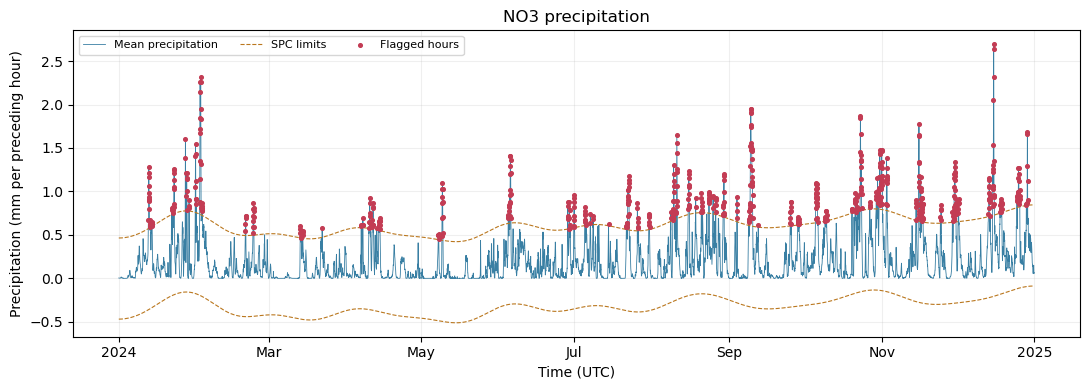

hours                              8784.000000
outlier_hours                       638.000000
outlier_percent                       7.263206
robust_sigma_mm                       0.155582
cutoff_days                          30.000000
deviations                            3.000000
maximum_hourly_precipitation_mm       2.693600
Name: DCT / SPC summary, dtype: float64

,precipitation,lower_limit,upper_limit,outlier
time,,,,
2024-12-15 18:00:00+00:00,2.6936,-0.206935,0.726556,True
2024-12-15 17:00:00+00:00,2.6352,-0.207291,0.726200,True
2024-02-02 18:00:00+00:00,2.3194,-0.200288,0.733203,True
2024-12-15 19:00:00+00:00,2.3181,-0.206578,0.726913,True
2024-02-02 17:00:00+00:00,2.2622,-0.199696,0.733795,True


In [14]:
spc_figure, spc_summary, precipitation_results = precipitation_spc(weather_hourly["precipitation"])
display(spc_figure)
display(pd.Series(spc_summary, name="DCT / SPC summary"))
display(precipitation_results.loc[precipitation_results["outlier"]].nlargest(5, "precipitation"))

### 3.2 Local Outlier Factor

Following the [course LOF example](https://github.com/khliland/IND320/blob/main/D2Dbook/3_Data_quality/2_Outliers/3_Anomaly_detection.ipynb), we use 20 neighbours and default contamination of 1%. The features are hourly mean temperature and its change from the preceding hour. Both are standardised so their units and spread do not dominate the distance.

The first hour has no preceding value and is not scored. LOF finds sparse combinations in this two-feature space. It does not prove an error or explicitly model the season. The selected contamination controls the threshold, so it must not be interpreted as a measured error rate.

In [15]:
def temperature_lof(series, contamination=0.01, neighbors=20, title="NO3 temperature"):
    """Flag unusual combinations of temperature and one-hour temperature change."""
    series = _regular_series(series, "1h", 48)
    if not 0 < contamination <= 0.5 or not 2 <= neighbors < len(series) - 1:
        raise ValueError("Use contamination in (0, 0.5] and a valid neighbour count.")
    features = pd.DataFrame({"temperature": series, "hourly_change": series.diff()}).iloc[1:]
    scaled = StandardScaler().fit_transform(features)
    model = LocalOutlierFactor(n_neighbors=neighbors, contamination=contamination)
    labels = model.fit_predict(scaled)
    result = pd.DataFrame({"temperature": series, "lof_score": np.nan, "anomaly": False})
    result.loc[features.index, "lof_score"] = -model.negative_outlier_factor_
    result.loc[features.index, "anomaly"] = labels == -1
    mask = result["anomaly"]
    summary = {
        "scored_hours": len(features), "anomaly_hours": int(mask.sum()),
        "anomaly_percent": 100 * mask.sum() / len(features),
        "contamination": contamination, "neighbors": neighbors,
        "score_threshold": -model.offset_,
    }
    fig = Figure(figsize=(11, 4))
    ax = fig.subplots()
    ax.plot(series.index, series, color="#397FA3", linewidth=0.6, label="Mean temperature")
    ax.scatter(series.index[mask], series[mask], color="#C33C54", s=12, label="LOF anomalies", zorder=3)
    ax.set(title=title, ylabel="Temperature (°C)", xlabel="Time (UTC)")
    ax.legend(fontsize=8)
    _date_axis(ax)
    fig.tight_layout()
    return fig, summary, result



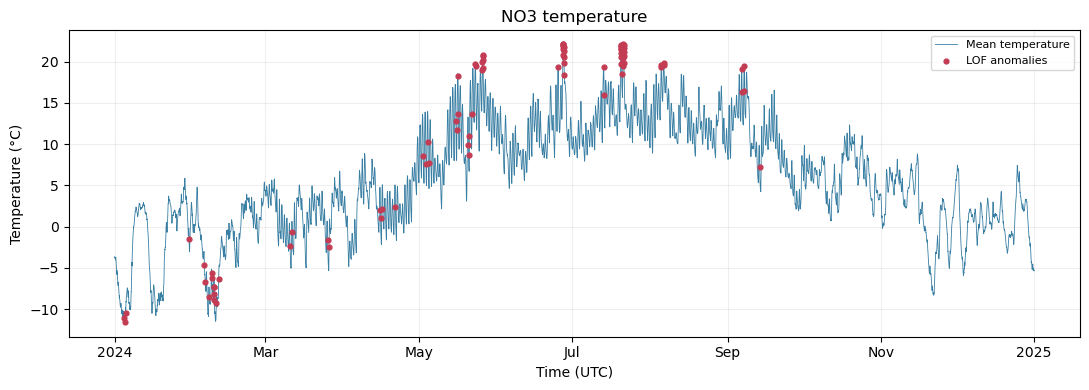

scored_hours       8783.000000
anomaly_hours        88.000000
anomaly_percent       1.001936
contamination         0.010000
neighbors            20.000000
score_threshold       1.268511
Name: LOF summary, dtype: float64

,temperature,lof_score,anomaly
time,,,
2024-02-09 16:00:00+00:00,-8.2092,2.272122,True
2024-02-09 15:00:00+00:00,-7.2908,2.158253,True
2024-02-10 10:00:00+00:00,-9.2667,1.944066,True
2024-05-22 06:00:00+00:00,13.6866,1.943712,True
2024-04-21 19:00:00+00:00,2.3439,1.813981,True


In [16]:
lof_figure, lof_summary, temperature_results = temperature_lof(weather_hourly["temperature_2m"])
display(lof_figure)
display(pd.Series(lof_summary, name="LOF summary"))
display(temperature_results.loc[temperature_results["anomaly"]].nlargest(5, "lof_score"))

### 3.3 Interpretation of the NO3 results

The complete dataset contains 1000 locations and 8784 hours for each variable. With a 30-day DCT cutoff and three robust standard deviations, SPC flags 638 hours (7.26%). The estimated residual scale is 0.156 mm. The largest regional mean is 2.694 mm in the hour ending 2024-12-15 18:00 UTC. These flags describe unusually wet or dry departures from the smooth baseline. They are not evidence that the underlying weather estimates are incorrect.

At 1% contamination, LOF flags 88 of 8783 scored hours. The largest LOF score occurs at 2024-02-09 16:00 UTC, when the regional mean temperature is -8.21 °C. The flags identify uncommon combinations of temperature and hourly change relative to the rest of the year. Their count is largely set by the chosen contamination, so a result near 1% does not independently validate the method.

The weather and reservoir examples refer to the same NO3 boundary, but this analysis does not estimate a causal weather effect on filling. Reservoir storage also depends on snow accumulation and melt, inflow delays, production and other operational decisions. Spatial averaging can hide local extremes, and nearby ERA5 requests are not independent observations.

## 4. Reservoir filling: STL and spectrogram

[NVE Magasinstatistikk](https://biapi.nve.no/magasinstatistikk/swagger/index.html) supplies weekly filling ratios. NO3 is `EL`, area number `3`, as in part 2. We use measurement dates and multiply the ratios by 100 to show percentages.

The weather example covers 2024. For the reservoir decomposition and spectrogram we use 2015–2024, since multiple annual cycles are needed to examine seasonality. Both methods use exactly the same weekly series. No interpolation is performed: duplicate dates, missing values or irregular intervals cause a clear error.

### 4.1 Seasonal-Trend decomposition using LOESS

The [course STL example](https://github.com/khliland/IND320/blob/main/D2Dbook/3_Data_quality/1_Signal/3_Decomposition.ipynb) and [statsmodels documentation](https://www.statsmodels.org/stable/generated/statsmodels.tsa.seasonal.STL.html) define the additive decomposition observed = trend + seasonal + residual. The period is 52 weekly observations, an approximation to a calendar year. ISO week 53 is kept rather than dropped.

Defaults are `seasonal=7`, `trend=105` and `robust=True`. The seasonal smoother acts across corresponding positions in successive cycles. The trend smoother spans roughly two years. Robust fitting reduces the influence of unusually large residuals. These parameters remain adjustable.

In [17]:
def reservoir_stl(series, seasonal=7, trend=105, robust=True, title="NO3 reservoir filling"):
    """Decompose regularly spaced weekly filling percentages with a 52-week period."""
    series = _regular_series(series, "7d", 104)
    if seasonal < 7 or seasonal % 2 != 1 or trend <= 52 or trend % 2 != 1:
        raise ValueError("Seasonal must be odd and at least 7; trend must be odd and greater than 52.")
    fitted = STL(series, period=52, seasonal=seasonal, trend=trend, robust=robust).fit()
    components = pd.DataFrame({"observed": series, "trend": fitted.trend,
                               "seasonal": fitted.seasonal, "residual": fitted.resid})
    fig = Figure(figsize=(11, 8))
    axes = fig.subplots(4, 1, sharex=True)
    for ax, column in zip(axes, components.columns):
        ax.plot(components.index, components[column], linewidth=0.9, color="#397FA3")
        ax.set_ylabel("Filling (%)" if column == "observed" else
                      "Trend (%)" if column == "trend" else f"{column.capitalize()} (pp)")
        _date_axis(ax)
    axes[0].set_title(title)
    axes[-1].set_xlabel("Measurement date")
    fig.tight_layout()
    return fig, components



NO3: 522 weekly observations, 2015-01-04 to 2024-12-29.


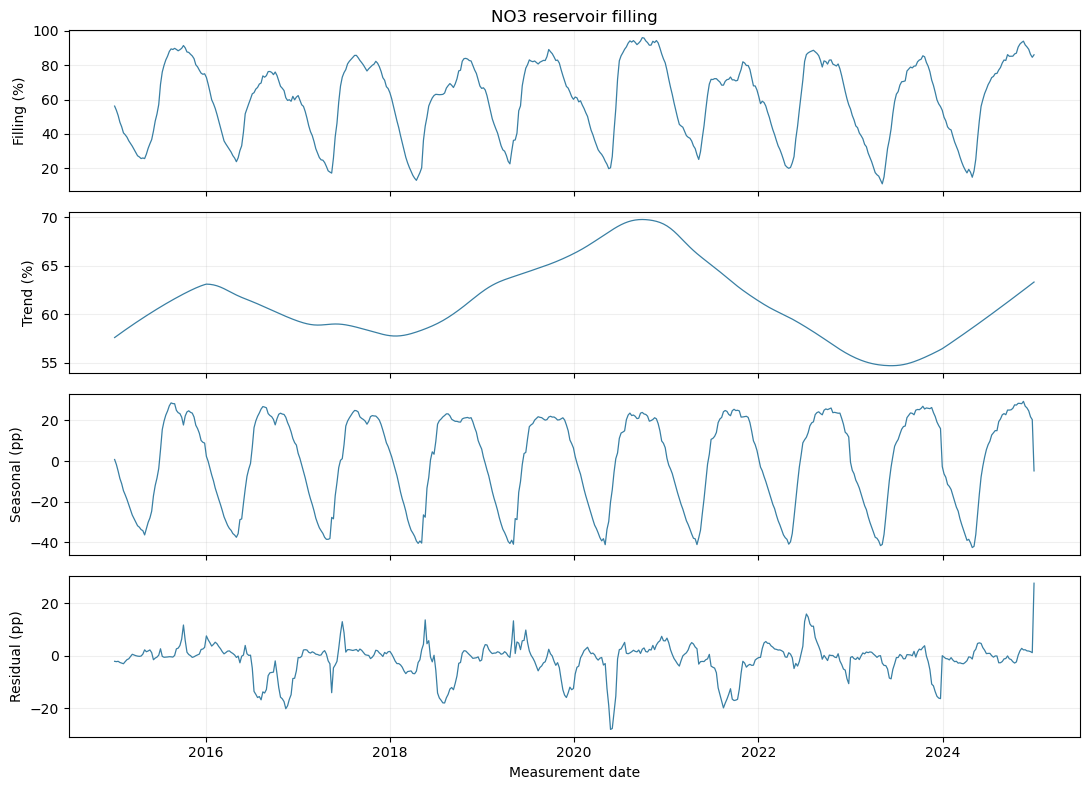

,observed,trend,seasonal,residual
count,522.00,522.00,522.00,522.00
mean,59.77,61.19,0.10,-1.52
std,22.78,3.95,22.58,6.35
min,10.90,54.72,-42.55,-28.12
25%,39.54,58.44,-20.72,-2.91
50%,63.89,60.57,6.67,-0.14
75%,79.87,63.42,21.27,1.78
max,96.10,69.78,29.34,27.61


In [18]:
# Reuse the preserved NVE response. Fetch it only if it is not available locally.
nve_source = Path("data/nve_reservoirs.json.gz")
if not nve_source.exists():
    response = requests.get(
        "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData", timeout=45
    )
    response.raise_for_status()
    with gzip.open(nve_source, "wb") as target:
        target.write(response.content)
with gzip.open(nve_source, "rt") as source:
    reservoir_data = pd.DataFrame(json.load(source))
reservoir_data["date"] = pd.to_datetime(reservoir_data["dato_Id"])
no3_reservoirs = reservoir_data.loc[
    reservoir_data["omrType"].eq("EL") & reservoir_data["omrnr"].eq(3)
    & reservoir_data["date"].between("2015-01-01", "2024-12-31")
].sort_values("date")
filling = no3_reservoirs.set_index("date")["fyllingsgrad"] * 100
filling.name = "filling_percent"
filling = _regular_series(filling, "7d", 104)
print(f"NO3: {len(filling)} weekly observations, {filling.index.min().date()} to {filling.index.max().date()}.")
stl_figure, stl_components = reservoir_stl(filling)
assert np.allclose(stl_components["observed"], stl_components[["trend", "seasonal", "residual"]].sum(axis=1))
display(stl_figure)
display(stl_components.describe().round(2))

The spectrogram below identifies an annual cycle, while STL separates the changing level from the recurring seasonal pattern. The large seasonal range indicates substantial annual filling and drawdown in NO3. Residuals remain because a fixed 52-week cycle and smooth components cannot explain every hydrological or operational change. The endpoint residual in late 2024 should be interpreted cautiously because STL has less neighbouring information at the ends.

### 4.2 Spectrogram of the same filling series

The [course spectrogram example](https://github.com/khliland/IND320/blob/main/D2Dbook/3_Data_quality/3_Preprocessing/5_Spectrograms.ipynb) uses `scipy.signal.stft`. We use a Hann window of 104 weeks and an overlap of 78 weeks. Each complete window spans roughly two years, and its mean is removed before the transform. No artificial zeros are added at the ends.

The horizontal axis shows window-centre dates. The vertical axis is cycles per year, not Hz. A signal repeating annually appears near 1 cycle/year. Colour shows STFT magnitude in percentage points. The two-year window gives roughly 0.5 cycles/year resolution. Longer windows resolve nearby frequencies better but locate changes less precisely in time.

In [19]:
def reservoir_spectrogram(series, window=104, overlap=78, title="NO3 filling spectrogram"):
    """STFT of the same weekly series, using complete windows without zero padding."""
    series = _regular_series(series, "7d", 104)
    if not 8 <= window <= len(series) or not 0 <= overlap < window:
        raise ValueError("Window must be between 8 and the series length; overlap must be smaller.")
    samples_per_year = 365.2425 / 7
    frequencies, times, spectrum = stft(
        series.to_numpy(), fs=samples_per_year, window="hann", nperseg=window,
        noverlap=overlap, detrend="constant", boundary=None, padded=False
    )
    dates = series.index[0] + pd.to_timedelta(times * 365.2425, unit="D")
    magnitude = np.abs(spectrum)
    fig = Figure(figsize=(11, 6))
    axes = fig.subplots(2, 1, sharex=True)
    axes[0].plot(series.index, series, color="#397FA3", linewidth=0.9)
    axes[0].set(ylabel="Filling (%)", title=title)
    _date_axis(axes[0])
    mesh = axes[1].pcolormesh(mdates.date2num(dates), frequencies, magnitude, shading="auto", cmap="magma")
    axes[1].set(ylabel="Frequency (cycles/year)", xlabel="Window centre date", ylim=(0, 4))
    axes[1].axhline(1, color="white", linestyle="--", linewidth=0.7)
    _date_axis(axes[1])
    fig.colorbar(mesh, ax=axes, label="STFT magnitude (pp)", fraction=0.03, pad=0.02)
    fig.subplots_adjust(left=0.09, right=0.85, bottom=0.1, top=0.94, hspace=0.18)
    summary = {"window_weeks": window, "overlap_weeks": overlap,
               "frequency_resolution_cycles_per_year": samples_per_year / window,
               "windows": len(times),
               "dominant_nonzero_frequency": frequencies[1:][np.argmax(magnitude[1:].mean(axis=1))]}
    return fig, summary


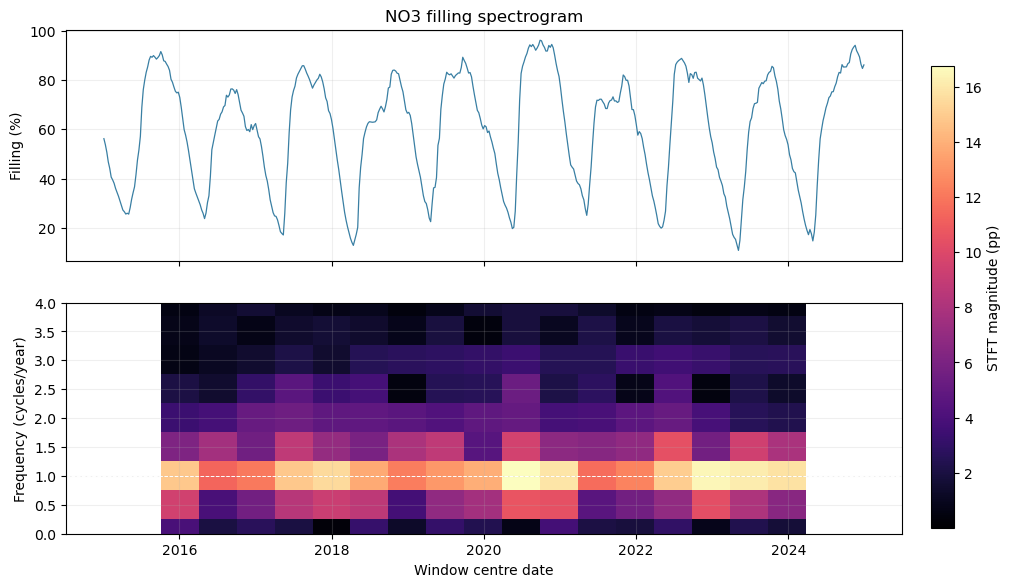

window_weeks                            104.000000
overlap_weeks                            78.000000
frequency_resolution_cycles_per_year      0.501707
windows                                  17.000000
dominant_nonzero_frequency                1.003413
Name: Spectrogram settings and result, dtype: float64

In [20]:
spectrogram_figure, spectrogram_summary = reservoir_spectrogram(filling)
display(spectrogram_figure)
display(pd.Series(spectrogram_summary, name="Spectrogram settings and result"))

## 5. Checks and Streamlit implementation

The checks below test reconstruction and anomaly detection using synthetic data with known structure. They supplement the checks on the real data, rather than treating a successful run as proof that the methods are correct.

The Streamlit app has two new pages. **Reservoir analysis** contains STL and Spectrogram tabs. **Weather quality** contains Precipitation / SPC and Temperature / LOF tabs. Both reuse the reservoir area type and period controls. An area-number selector is shared between the analysis pages. The weather page requires months within a single completed year, because SPC statistics are estimated from the full year. Only the selected months are displayed.

Weather for other EL and course VASS groups can be downloaded from the weather page. Download control is integrated there, and cached data are reused when only plot parameters change. The Norway total has no separate point sample, so the app asks for an EL or VASS area rather than assigning an unrelated weather series.

The functions defined in this notebook are exported to `data_quality.py` for Streamlit. This keeps the notebook as the documented implementation and lets both interfaces run the same calculations.

In [21]:
# Known anomalies and a known annual cycle test the behaviour of the methods.
rng = np.random.default_rng(123)
test_time = pd.date_range("2024-01-01", periods=8784, freq="h", tz="UTC")
test_precipitation = pd.Series(0.2 + rng.normal(0, 0.01, len(test_time)), index=test_time)
test_precipitation.iloc[4000] = 5
_, _, test_spc = precipitation_spc(test_precipitation)
assert test_spc.iloc[4000]["outlier"]
test_temperature = pd.Series(rng.normal(5, 1, len(test_time)), index=test_time)
test_temperature.iloc[4000] = 50
_, _, test_lof = temperature_lof(test_temperature)
assert test_lof.iloc[4000]["anomaly"]
test_weeks = pd.date_range("2015-01-04", periods=522, freq="7d")
test_filling = pd.Series(60 + 20 * np.sin(2 * np.pi * np.arange(522) / 52), index=test_weeks)
_, test_stl = reservoir_stl(test_filling)
assert np.allclose(test_stl["observed"], test_stl[["trend", "seasonal", "residual"]].sum(axis=1))
_, test_spectrum = reservoir_spectrogram(test_filling)
assert abs(test_spectrum["dominant_nonzero_frequency"] - 1) < 0.1
print("Injected precipitation and temperature anomalies detected.")
print("STL reconstructs the input; the spectrogram recovers the annual cycle.")

Injected precipitation and temperature anomalies detected.
STL reconstructs the input; the spectrogram recovers the annual cycle.


In [22]:
# Export only the reusable definitions, not downloads, displays or fitted results.
import nbformat
notebook = nbformat.read("prosjekt_del_3.ipynb", as_version=4)
shared_cells = [cell.source for cell in notebook.cells
                if any(tag.startswith("shared-") for tag in cell.metadata.get("tags", []))]
Path("data_quality.py").write_text(
    '"""Generated from the shared function cells in prosjekt_del_3.ipynb."""\n\n'
    + "\n\n".join(shared_cells)
)
print("Streamlit uses the same weather and analysis functions as this notebook.")

Streamlit uses the same weather and analysis functions as this notebook.


## 6. Work log

The work started with the two geographical divisions in the assignment. The NVE administrative polygons were merged into East, West and North, while the five electricity bidding areas were kept separate. Comparing the maps clarified why the two sets of boundaries are useful: weather must be summarised over the same geographical group as the selected reservoir series. The 8000 sampled points belong to eight alternative regions, not to one national sample. Geometry checks confirmed that the merges preserved coverage and that each sampled point was inside its assigned polygon.

The next step was the Open-Meteo request for NO3 in 2024. The historical API documentation provided the variable names, ERA5 model selection and units. Requesting several coordinates together reduced the number of HTTP requests, but did not remove the service's usage limits. Saving each raw response made the download resumable. The complete point arrays are retained, and the hourly regional mean is calculated only after checking the time axis, units, dimensions and missing values. This separates data retrieval from subsequent parameter changes.

The statistical methods were implemented as functions in the notebook. Precipitation uses DCT filtering followed by robust SPC limits, while temperature uses LOF on temperature and hourly change. Both methods flag observations for inspection rather than deleting them. For reservoir filling, a longer period was selected because one year provides too little information about recurring annual variation. STL and the spectrogram use the same weekly series, making their results easier to compare. Synthetic signals with known anomalies and an annual cycle provide checks beyond simply running the code.

The Streamlit work reused the existing reservoir controls and added two pages with two tabs each. Separating full-year fitting from the displayed months keeps weather thresholds consistent when the visible period changes. A navigation test revealed that Streamlit could reset the selected area when changing pages. Explicitly preserving widget state addressed this interaction. The notebook remains the source of the shared functions, which are exported for use by the app. This avoids maintaining separate statistical implementations. The main practical lessons were to check geographical meaning before joining data, preserve expensive API responses, and test interface state as well as individual calculations.

## 7. Use of AI

An AI coding assistant helped interpret the assignment, inspect the linked documentation and course examples, write and revise Python code and English explanations, and run local checks. It also drafted this work log from the recorded workflow. The implementation and written interpretation require the author's review. The ERA5 and NVE observations come from the cited data services, not from AI-generated data.